<a href="https://colab.research.google.com/github/Mondayszz/PORTOFOLIO/blob/main/Solar%20Photovoltaic%20System%20Data%20Analysis%20%26%20Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [ ]:
# 1. Load semua sheet dari Excel (header di baris ke-3 = header=2)
file_path = '/content/drive/My Drive/LTSM/DATA SISTEM PVT_A-B TERPISAH.xlsx'
all_sheets = pd.read_excel(file_path, sheet_name=None, header=2)

# 2. Gabungkan semua sheet jadi satu DataFrame
list_df = []
for sheet, df in all_sheets.items():
    df['sheet'] = sheet
    list_df.append(df)
raw_data = pd.concat(list_df, ignore_index=True)

# 3. Rapikan nama kolom & hilangkan duplikat
raw_data.columns = raw_data.columns.str.strip()
raw_data = raw_data.loc[:, ~raw_data.columns.duplicated()]

# 4. Bersihkan error & konversi kolom angka
raw_data = raw_data.replace('#VALUE!', np.nan)
tegangan_columns = ['Tegangan A', 'Tegangan B']
cols_to_convert = [col for col in raw_data.columns if col not in ["Time", "Ket. Cuaca", "sheet"] and raw_data[col] is not None and raw_data[col].ndim == 1]
raw_data[cols_to_convert] = raw_data[cols_to_convert].apply(pd.to_numeric, errors='coerce')

# 5. Cleaning: Drop NA hanya untuk Tegangan A, Tegangan B, dan Time (cuaca boleh NaN, nanti diisi 'Unknown')
data = raw_data.dropna(subset=['Time', 'Tegangan A', 'Tegangan B']).copy()
data['Ket. Cuaca'] = data['Ket. Cuaca'].fillna('Unknown')

# 6. Parsing waktu universal (otomatis deteksi format sheet dan time)
def parse_waktu_universal(row):
    sheet = str(row['sheet'])
    time = str(row['Time'])
    # Normalisasi Time
    if time.count(':') == 1 and len(time) <= 5:
        time = time.zfill(5)
    elif time.count(':') == 2 and len(time) <= 7:
        time = time.zfill(8)
    waktu_str = f"{sheet} {time}"
    # Sheet 8 digit: %d%m%Y, Sheet 6 digit: %d%m%y
    if len(sheet) == 8:
        for fmt in ['%d%m%Y %H:%M', '%d%m%Y %H:%M:%S']:
            try:
                return pd.to_datetime(waktu_str, format=fmt)
            except:
                continue
    elif len(sheet) == 6:
        for fmt in ['%d%m%y %H:%M', '%d%m%y %H:%M:%S']:
            try:
                return pd.to_datetime(waktu_str, format=fmt)
            except:
                continue
    return pd.NaT

data['waktu'] = data.apply(parse_waktu_universal, axis=1)
print("Distribusi data per sheet setelah parsing waktu, sebelum dropna:")
print(data.loc[data['waktu'].notna(), 'sheet'].value_counts())
data = data.dropna(subset=['waktu'])

# 7. Encode kondisi cuaca
le = LabelEncoder()
data['cuaca_enc'] = le.fit_transform(data['Ket. Cuaca'].astype(str))

# 8. Scaling tegangan
scaler = MinMaxScaler()
data[['teganganA_norm', 'teganganB_norm']] = scaler.fit_transform(data[tegangan_columns])

# 9. Info: Cek distribusi sheet yang ikut
print("Distribusi data per sheet setelah cleaning:")
print(data['sheet'].value_counts())

Distribusi data per sheet setelah parsing waktu, sebelum dropna:
sheet
051024      21
101024      21
121024      21
111024      21
04102024    19
091024      19
Name: count, dtype: int64
Distribusi data per sheet setelah cleaning:
sheet
051024      21
101024      21
121024      21
111024      21
04102024    19
091024      19
Name: count, dtype: int64


/tmp/ipython-input-38-2315532615.py:17: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  raw_data = raw_data.replace('#VALUE!', np.nan)


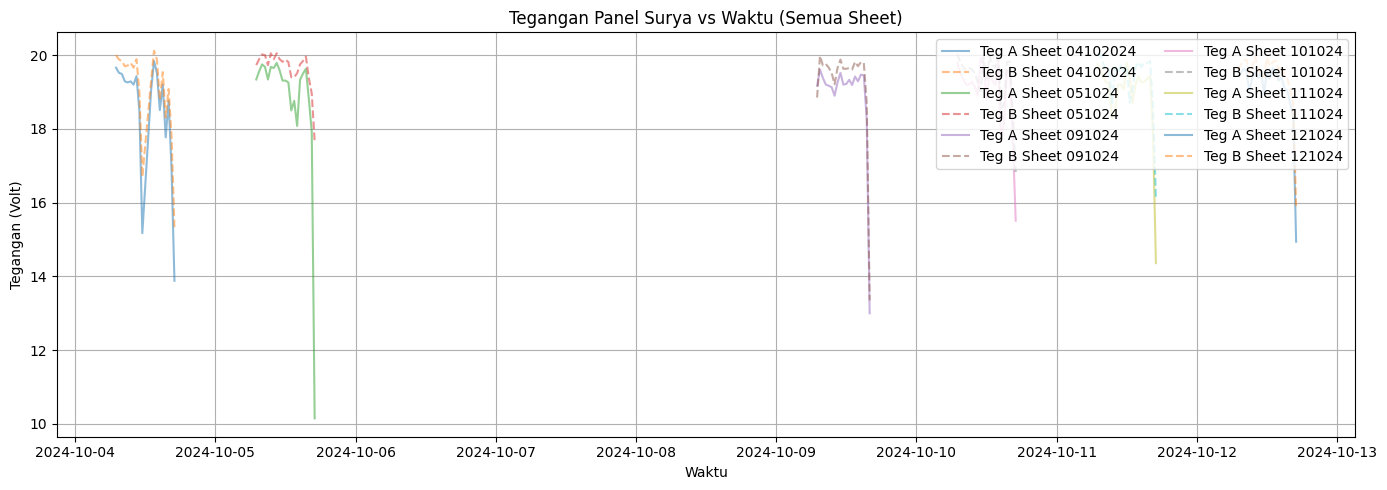

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - loss: 1.2776 - val_loss: 0.1784
Epoch 2/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1488 - val_loss: 0.0607
Epoch 3/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0799 - val_loss: 0.0239
Epoch 4/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0851 - val_loss: 0.0254
Epoch 5/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0385 - val_loss: 0.0199
Epoch 6/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0448 - val_loss: 0.0207
Epoch 7/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0676 - val_loss: 0.0177
Epoch 8/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0407 - val_loss: 0.0173
Epoch 9/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0541 - val_loss: 0.0224
Epoch 10/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0382 - val_loss: 0.0178
Epoch 11/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0241 - val_loss: 0.0190
Epoch 12/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.03

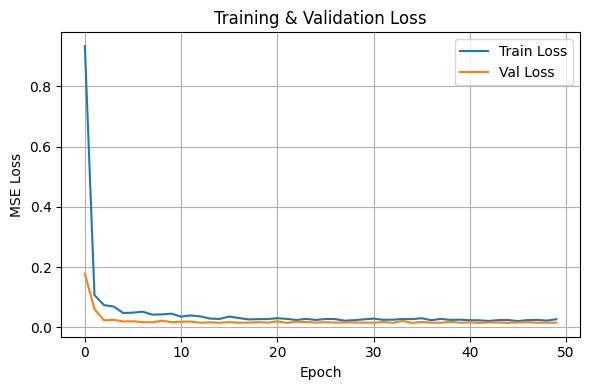

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 279ms/step
Evaluasi Tegangan A:
MAE: 0.828 | RMSE: 1.161 | R²: 0.248
Evaluasi Tegangan B:
MAE: 0.653 | RMSE: 0.901 | R²: 0.254


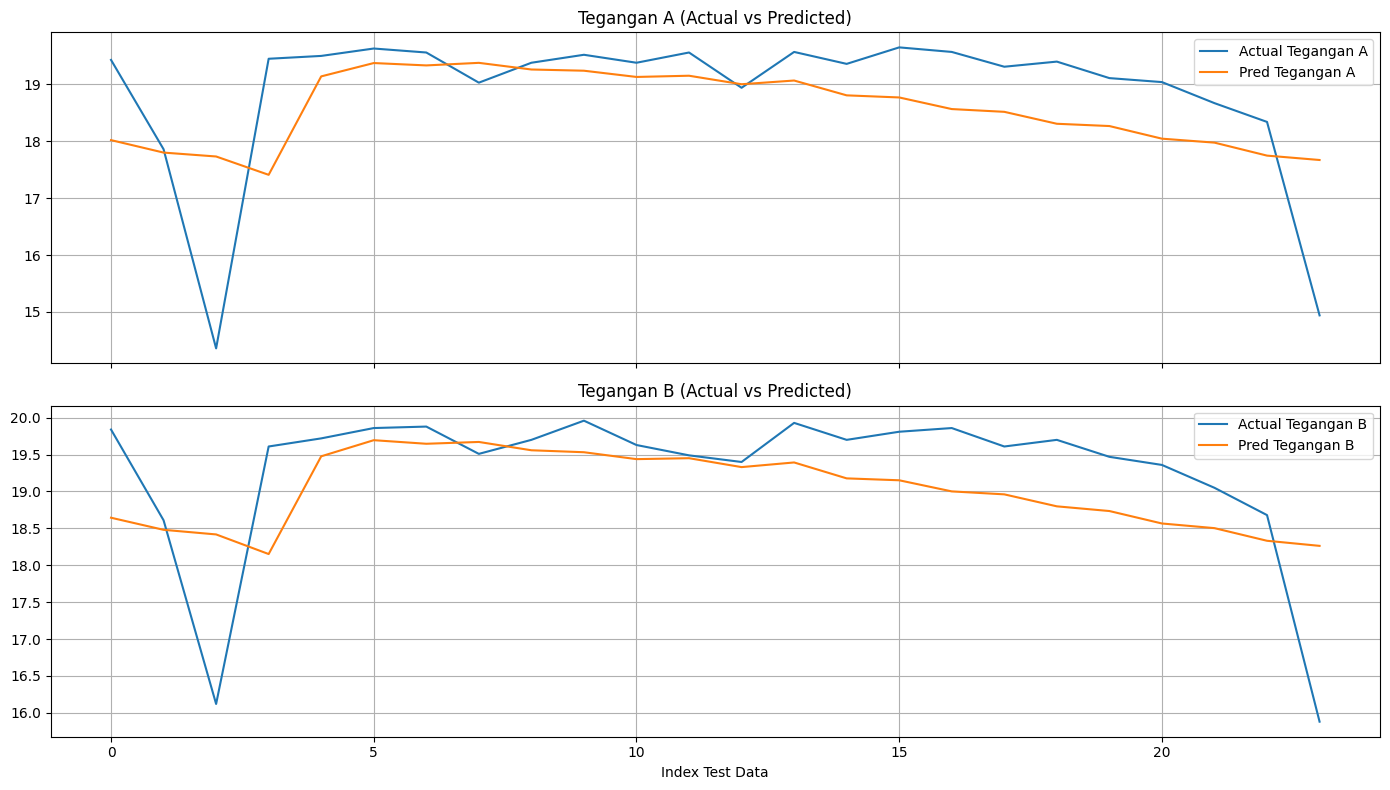

Jam: 2024-10-11 16:00:00, TeganganA Actual: 19.43, Pred: 18.02, Klasifikasi: optimal | TeganganB Actual: 19.84, Pred: 18.64, Klasifikasi: optimal
Jam: 2024-10-11 16:30:00, TeganganA Actual: 17.86, Pred: 17.80, Klasifikasi: cukup | TeganganB Actual: 18.61, Pred: 18.48, Klasifikasi: optimal
Jam: 2024-10-11 17:00:00, TeganganA Actual: 14.36, Pred: 17.73, Klasifikasi: cukup | TeganganB Actual: 16.12, Pred: 18.42, Klasifikasi: optimal
Jam: 2024-10-12 07:00:00, TeganganA Actual: 19.45, Pred: 17.41, Klasifikasi: cukup | TeganganB Actual: 19.61, Pred: 18.15, Klasifikasi: optimal
Jam: 2024-10-12 07:30:00, TeganganA Actual: 19.50, Pred: 19.14, Klasifikasi: optimal | TeganganB Actual: 19.72, Pred: 19.48, Klasifikasi: optimal
Jam: 2024-10-12 08:00:00, TeganganA Actual: 19.63, Pred: 19.37, Klasifikasi: optimal | TeganganB Actual: 19.86, Pred: 19.70, Klasifikasi: optimal
Jam: 2024-10-12 08:30:00, TeganganA Actual: 19.56, Pred: 19.33, Klasifikasi: optimal | TeganganB Actual: 19.88, Pred: 19.65, Klasi

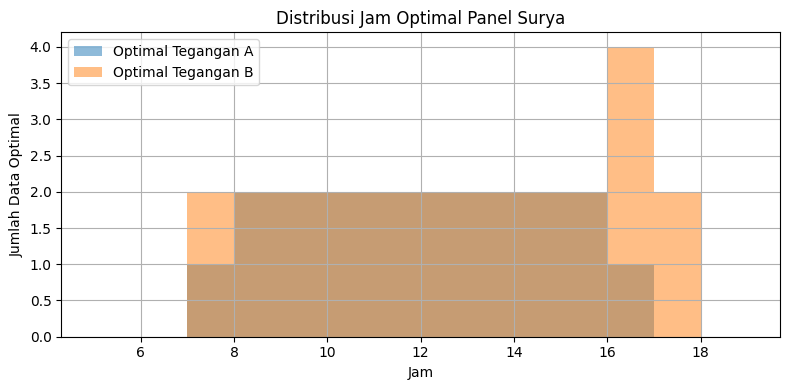

In [ ]:
# 10. Visualisasi Data Awal Tegangan A & B (semua sheet)
plt.figure(figsize=(14,5))
for sheet in data['sheet'].unique():
    subset = data[data['sheet']==sheet]
    plt.plot(subset['waktu'], subset['Tegangan A'], label=f'Teg A Sheet {sheet}', alpha=0.5)
    plt.plot(subset['waktu'], subset['Tegangan B'], label=f'Teg B Sheet {sheet}', alpha=0.5, linestyle='dashed')
plt.title('Tegangan Panel Surya vs Waktu (Semua Sheet)')
plt.xlabel('Waktu')
plt.ylabel('Tegangan (Volt)')
plt.legend(loc='upper right', ncol=2)
plt.grid(True)
plt.tight_layout()
plt.show()

# 11. Buat dataset sequence LSTM (misal: 6 jam sebelumnya), target = [teganganA_norm, teganganB_norm]
def create_sequences(df, seq_length=6):
    X, y = [], []
    df = df.sort_values('waktu').reset_index(drop=True)
    for i in range(len(df) - seq_length):
        fitur_waktu = df['waktu'].dt.hour.iloc[i:i+seq_length].values.reshape(-1, 1)
        fitur_cuaca = df['cuaca_enc'].iloc[i:i+seq_length].values.reshape(-1, 1)
        fitur = np.hstack([fitur_waktu, fitur_cuaca])
        X.append(fitur)
        y.append(df[['teganganA_norm', 'teganganB_norm']].iloc[i+seq_length].values)
    return np.array(X), np.array(y)

seq_length = 6
X, y = create_sequences(data, seq_length=seq_length)
if len(X) == 0:
    raise ValueError("Data terlalu sedikit untuk membuat sequence LSTM. Periksa hasil cleaning data Anda!")

# 12. Split data (train/test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# 13. Bangun model LSTM (output 2 neuron, multi-output regression)
model = Sequential([
    LSTM(64, input_shape=(seq_length, X.shape[2]), return_sequences=False),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(2, activation='linear')
])
model.compile(optimizer='adam', loss='mse')

# 14. Training model
history = model.fit(X_train, y_train, epochs=50, batch_size=8, validation_data=(X_test, y_test))

# 15. Plot loss training
plt.figure(figsize=(6,4))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Training & Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 16. Prediksi & klasifikasi
y_pred = model.predict(X_test)
y_pred_actual = scaler.inverse_transform(y_pred)
y_test_actual = scaler.inverse_transform(y_test)

def classify_tegangan(val):
    if val >= 18:
        return "optimal"
    elif val >= 12:
        return "cukup"
    else:
        return "kurang"

klasifikasi_A = [classify_tegangan(v[0]) for v in y_pred_actual]
klasifikasi_B = [classify_tegangan(v[1]) for v in y_pred_actual]

# 17. Evaluasi model
print("Evaluasi Tegangan A:")
mae_A = mean_absolute_error(y_test_actual[:,0], y_pred_actual[:,0])
rmse_A = np.sqrt(mean_squared_error(y_test_actual[:,0], y_pred_actual[:,0]))
r2_A = r2_score(y_test_actual[:,0], y_pred_actual[:,0])
print(f"MAE: {mae_A:.3f} | RMSE: {rmse_A:.3f} | R²: {r2_A:.3f}")

print("Evaluasi Tegangan B:")
mae_B = mean_absolute_error(y_test_actual[:,1], y_pred_actual[:,1])
rmse_B = np.sqrt(mean_squared_error(y_test_actual[:,1], y_pred_actual[:,1]))
r2_B = r2_score(y_test_actual[:,1], y_pred_actual[:,1])
print(f"MAE: {mae_B:.3f} | RMSE: {rmse_B:.3f} | R²: {r2_B:.3f}")

# 18. Plot hasil prediksi
fig, axs = plt.subplots(2, 1, figsize=(14,8), sharex=True)
axs[0].plot(y_test_actual[:,0], label='Actual Tegangan A')
axs[0].plot(y_pred_actual[:,0], label='Pred Tegangan A')
axs[0].set_title('Tegangan A (Actual vs Predicted)')
axs[0].legend()
axs[0].grid(True)
axs[1].plot(y_test_actual[:,1], label='Actual Tegangan B')
axs[1].plot(y_pred_actual[:,1], label='Pred Tegangan B')
axs[1].set_title('Tegangan B (Actual vs Predicted)')
axs[1].legend()
axs[1].grid(True)
plt.xlabel('Index Test Data')
plt.tight_layout()
plt.show()

# 19. Tampilkan sampel hasil prediksi & klasifikasi
for i in range(min(10, len(y_test_actual))):
    idx = len(X_train) + seq_length + i
    waktu_str = data['waktu'].iloc[idx] if idx < len(data) else "-"
    print(f"Jam: {waktu_str}, "
          f"TeganganA Actual: {y_test_actual[i,0]:.2f}, Pred: {y_pred_actual[i,0]:.2f}, Klasifikasi: {klasifikasi_A[i]} | "
          f"TeganganB Actual: {y_test_actual[i,1]:.2f}, Pred: {y_pred_actual[i,1]:.2f}, Klasifikasi: {klasifikasi_B[i]}")

# 20. (Opsional) Simpan hasil ke CSV
hasil_df = pd.DataFrame({
    'waktu': [data['waktu'].iloc[len(X_train)+seq_length+i] if (len(X_train)+seq_length+i)<len(data) else '-' for i in range(len(y_test_actual))],
    'TeganganA_Actual': y_test_actual[:,0],
    'TeganganA_Pred': y_pred_actual[:,0],
    'Klasifikasi_A': klasifikasi_A,
    'TeganganB_Actual': y_test_actual[:,1],
    'TeganganB_Pred': y_pred_actual[:,1],
    'Klasifikasi_B': klasifikasi_B
})
hasil_df.to_csv('hasil_prediksi_tegangan_panel_surya_AB.csv', index=False)

# 21. Analisis waktu paling optimal
hasil_df['hour'] = hasil_df['waktu'].apply(lambda x: pd.to_datetime(x).hour if x != '-' else np.nan)
optimal_A = hasil_df[hasil_df['Klasifikasi_A'] == 'optimal']
optimal_B = hasil_df[hasil_df['Klasifikasi_B'] == 'optimal']

print("\nDistribusi jam optimal Tegangan A:")
print(optimal_A['hour'].value_counts().sort_index())
print("\nDistribusi jam optimal Tegangan B:")
print(optimal_B['hour'].value_counts().sort_index())

jam_opt_A = optimal_A['hour'].unique()
jam_opt_B = optimal_B['hour'].unique()
jam_opt_keduanya = np.intersect1d(jam_opt_A, jam_opt_B)

print(f"\nJam optimal Tegangan A: {np.sort(jam_opt_A)}")
print(f"Jam optimal Tegangan B: {np.sort(jam_opt_B)}")
print(f"Jam optimal di keduanya: {np.sort(jam_opt_keduanya)}")

# (Opsional) Visualisasi distribusi jam optimal
plt.figure(figsize=(8,4))
plt.hist(optimal_A['hour'].dropna(), bins=range(5,20), alpha=0.5, label='Optimal Tegangan A')
plt.hist(optimal_B['hour'].dropna(), bins=range(5,20), alpha=0.5, label='Optimal Tegangan B')
plt.xlabel('Jam')
plt.ylabel('Jumlah Data Optimal')
plt.title('Distribusi Jam Optimal Panel Surya')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 22. (Opsional) Simpan model
# model.save('lstm_pvpanel_model_AB.h5')